# Multimodale Maschinenüberwachung

Gemeinsames Notebook für die nacheinander zu bearbeitenden Exercises 16.1–16.4. Aktuell ist ausschließlich 16.1 umgesetzt.

## Exercise 16.1 – Vibration CNN

### Ziel und Anforderungen
Formen, Klassen und Datenqualität des offiziellen synthetischen Datensatzes untersuchen; pro Klasse ein Vibrationssignal und ein Wärmebild mit gemeinsamer Farbskala zeigen. Gepaarter stratifizierter 80/20-Split (Seed 42), je Modalität ein TRAIN-Mittelwert und eine TRAIN-Standardabweichung; Array- und Tensorformen ausgeben. Die vorgegebene `TimeSeriesCNN` mit 32 Features und drei Logits vervollständigen, Dropout/train/eval und Pooling erklären. Mit dem vorgegebenen Adam-/Kreuzentropie-Rahmen 30 Epochen und Batchgröße 16 auf Vibration trainieren. TEST-Confusion-Matrix sowie Kreuztabellen des verborgenen Vibrationslevels mit wahren/vorhergesagten Klassen interpretieren. Verborgene Levels dienen ausschließlich dieser Diagnose.

Quelle: [offizielle Exercise 16.1 und vollständige Codevorlagen](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/3_self_study_session3.html), Abruf 21.11.2026. Ein gemeinsames Notebook ist ausdrücklich vorgeschrieben. Abnahme: alle genannten Tabellen, Formen, zwei erforderlichen Abbildungen und verständliche Interpretation; Notebook und Offline-HTML, ergänzende CSV/JSON-Prüfartefakte. Keine Umsetzung von 16.2–16.4.

Die Kursdaten und das Manuskript stehen unter CC BY-NC-SA 4.0 (Gregor Ehrensperger). Original-JSON unverändert unter `data/raw/sss3_multimodal.json`; Quelle und SHA256 in `data/raw/MULTIMODAL_SOURCE.md`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, accuracy_score
from IPython.display import display
from sessions.ch16.multimodal import (load_multimodal_data, prepare_data, TimeSeriesCNN, train_model, predict_proba, DATA_PATH, RAW_SHA256, NAMES, SEED)
output=Path("outputs/ch16/exercise_16_1")
output.mkdir(parents=True,exist_ok=True)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
ts_data,img_data,labels,levels=load_multimodal_data(str(DATA_PATH))
display(pd.DataFrame([{"Array":name,"Shape":str(a.shape),"Typ":str(a.dtype),"Nicht endlich":int((~np.isfinite(a)).sum())} for name,a in zip(["ts_data","img_data","labels","levels"],[ts_data,img_data,labels,levels])]))
prepared=prepare_data(ts_data,img_data,labels,levels)
# Original frame names remain available for later exercises in this notebook.
ts_train,ts_test=prepared["ts_train"],prepared["ts_test"]
img_train,img_test=prepared["img_train"],prepared["img_test"]
y_train,y_test=prepared["y_train"],prepared["y_test"]
levels_train,levels_test=prepared["levels_train"],prepared["levels_test"]
ts_train_norm,ts_test_norm=prepared["ts_train_norm"],prepared["ts_test_norm"]
img_train_norm,img_test_norm=prepared["img_train_norm"],prepared["img_test_norm"]
ts_train_tensor,ts_test_tensor=prepared["ts_train_tensor"],prepared["ts_test_tensor"]
img_train_tensor,img_test_tensor=prepared["img_train_tensor"],prepared["img_test_tensor"]
y_train_tensor=prepared["y_train_tensor"]
ts_mean,ts_std=prepared["ts_mean"],prepared["ts_std"]
img_mean,img_std=prepared["img_mean"],prepared["img_std"]
class_counts=pd.DataFrame({"Klasse":NAMES,"Gesamt":np.bincount(labels,minlength=3),"TRAIN":np.bincount(y_train,minlength=3),"TEST":np.bincount(y_test,minlength=3)})
display(class_counts)
class_counts.to_csv(output/"class_counts.csv",index=False)


,Array,Shape,Typ,Nicht endlich
0,ts_data,"(500, 80)",float64,0
1,img_data,"(500, 32, 32)",float64,0
2,labels,"(500,)",int64,0
3,levels,"(500, 2)",int64,0


,Klasse,Gesamt,TRAIN,TEST
0,Normal,240,192,48
1,Warning,185,148,37
2,Critical,75,60,15


### Ein Beispiel je Gesundheitsklasse
Als reproduzierbare Illustration wird die erste TRAIN-Beobachtung je Klasse gewählt, nicht ein nachträglich besonders deutliches Beispiel. Drei Beispiele repräsentieren nicht die gesamte Streuung. Alle Bilder verwenden das globale Temperaturintervall 11,4–68,6 °C ausschließlich zur Darstellung; es fließt nicht in die Vorverarbeitung ein. Vibrationsamplitude ohne spezifizierte physikalische Einheit, Zeit als Abtastindex.

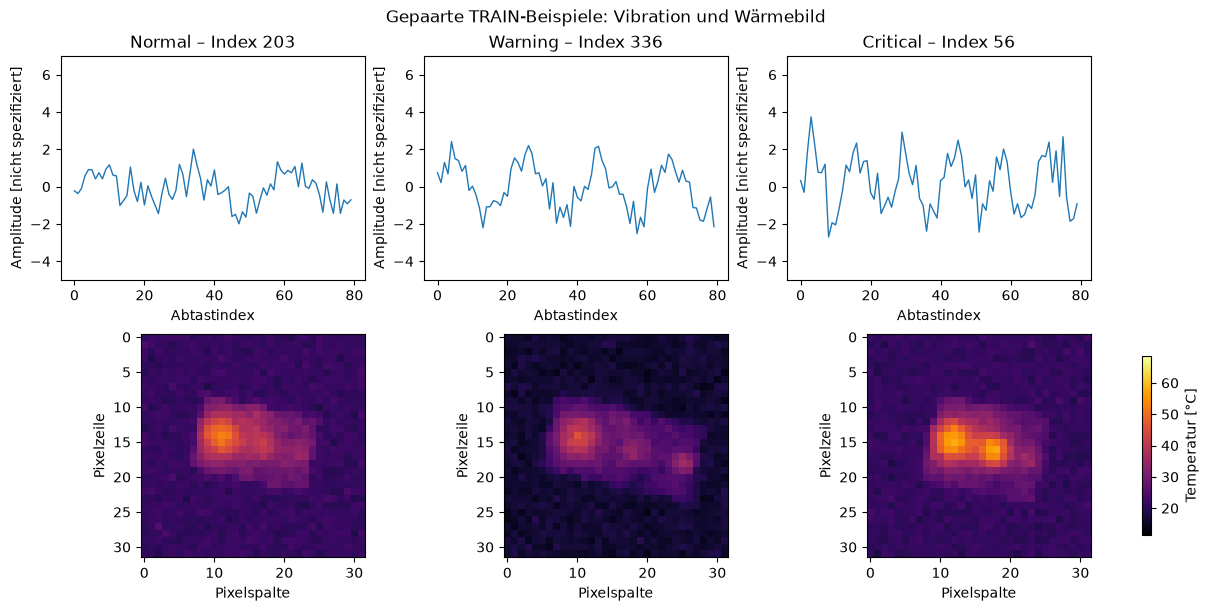

In [2]:
fig,axes=plt.subplots(2,3,figsize=(12,6),layout="constrained")
examples=[]
for status,name in enumerate(NAMES):
    local_index=np.flatnonzero(y_train==status)[0]
    index=int(prepared["train_indices"][local_index])
    examples.append({"Klasse":name,"Index_0basiert":index})
    axes[0,status].plot(np.arange(80),ts_data[index],lw=1)
    axes[0,status].set(title=f"{name} – Index {index}",xlabel="Abtastindex",ylabel="Amplitude [nicht spezifiziert]",ylim=(-5,7))
    image=axes[1,status].imshow(img_data[index],cmap="inferno",vmin=img_data.min(),vmax=img_data.max(),origin="upper")
    axes[1,status].set(xlabel="Pixelspalte",ylabel="Pixelzeile")
fig.colorbar(image,ax=axes[1,:],label="Temperatur [°C]",shrink=.8)
fig.suptitle("Gepaarte TRAIN-Beispiele: Vibration und Wärmebild")
fig.savefig(output/"01_class_examples.png",dpi=150,bbox_inches="tight")
plt.show()
pd.DataFrame(examples).to_csv(output/"example_indices.csv",index=False)


Das Wärmebild zeigt das Gehäuse und warme Bereiche der Bauteile: Motor links, Getriebe mittig, Lager rechts sowie Steuerung oben. Unten liegt der kühlere Lufteinlass. Diese Zuordnung stammt aus der Simulationserklärung; Lage und Drehung variieren, eine einzelne helle Stelle ist kein Beweis für ein bestimmtes Bauteil. Temperatur hängt auch von der Last ab. Ein thermisches Problem betrifft Getriebe/Lager relativ zur am Motor sichtbaren Last. Im gezeigten Warning-Beispiel ist das Bild insgesamt kühler als im Normal-Beispiel; beim Critical-Beispiel fällt ein stärkerer warmer Bereich in Gehäusemitte auf. Die Gesamthelligkeit ordnet die Klassen also nicht einfach. Die Beispiele zeigen Unterschiede, begründen aber keine sichere Trennung per Augenmaß. Benachbarte Vibrationslevel überlappen.

### Vorverarbeitung und CNN
Alle Modalitäten, Labels und Diagnoselevel behalten dieselben Indizes. Je Modalität wird über **alle TRAIN-Werte** ein Mittelwert und eine Standardabweichung (ddof=0) berechnet; dieselben zwei Zahlen werden auf TEST angewendet. Kein bildweises oder zeitpunktweises Fitten, keine TEST-Statistik zur Skalierung.

Ein 1D-CNN verschiebt lernbare Filter entlang des Signals und erkennt lokale Muster. Zwei Blöcke Conv1d (1→16→32, Kernel 5, same) + ReLU + MaxPool1d(2) verkürzen 80→40→20 Werte. AvgPool1d(20) mittelt danach je Kanal zu einem Wert; Flatten und Linear(32,32)+ReLU ergeben 32 Features, Dropout(0,3) und Linear(32,3) drei Logits. Kein Softmax vor CrossEntropyLoss.

Dropout setzt im Training zufällig einzelne Aktivierungen mit Wahrscheinlichkeit 0,3 auf null und skaliert die übrigen mit 1/0,7. Das erschwert ein zu starkes Verlassen auf einzelne Aktivierungen und kann Überanpassung begrenzen, garantiert sie aber nicht. `model.train()` aktiviert dieses Verhalten. `model.eval()` deaktiviert es: Bei der Vorhersage sollen alle gelernten Aktivierungen stabil verwendet werden. `no_grad()` verhindert zusätzlich die unnötige Gradientenberechnung; es ersetzt `eval()` nicht.

Max Pooling behält den größten Wert eines Fensters und betont starke lokale Aktivierungen; Average Pooling bildet den Mittelwert. Hier verdichtet das abschließende Average Pooling die 20 verbleibenden Positionen zu einem Wert je Kanal. Quellen, gelesen 21.11.2026: [Dropout](https://docs.pytorch.org/docs/2.9/generated/torch.nn.Dropout.html), [AvgPool1d](https://docs.pytorch.org/docs/2.9/generated/torch.nn.AvgPool1d.html), [MaxPool1d](https://docs.pytorch.org/docs/2.9/generated/torch.nn.MaxPool1d.html).

In [3]:
shape_rows=[]
for name in ["ts_train","ts_test","img_train","img_test","y_train","y_test","levels_train","levels_test","ts_train_norm","ts_test_norm","img_train_norm","img_test_norm","ts_train_tensor","ts_test_tensor","img_train_tensor","img_test_tensor","y_train_tensor"]:
    shape_rows.append({"Name":name,"Shape":str(tuple(prepared[name].shape))})
shapes=pd.DataFrame(shape_rows)
display(shapes)
shapes.to_csv(output/"shapes.csv",index=False)
scaling={k:prepared[k] for k in ["ts_mean","ts_std","img_mean","img_std"]}
display(pd.DataFrame([scaling]))
(output/"scaling.json").write_text(json.dumps(scaling,indent=2),encoding="utf-8")
print("features:",tuple(TimeSeriesCNN().features(ts_train_tensor[:4]).shape))
print("logits:",tuple(TimeSeriesCNN()(ts_train_tensor[:4]).shape))
assert TimeSeriesCNN().features(ts_train_tensor[:4]).shape==(4,32)
assert TimeSeriesCNN()(ts_train_tensor[:4]).shape==(4,3)


,Name,Shape
0,ts_train,"(400, 80)"
1,ts_test,"(100, 80)"
2,img_train,"(400, 32, 32)"
3,img_test,"(100, 32, 32)"
4,y_train,"(400,)"
5,y_test,"(100,)"
6,levels_train,"(400, 2)"
7,levels_test,"(100, 2)"
8,ts_train_norm,"(400, 80)"
9,ts_test_norm,"(100, 80)"


,ts_mean,ts_std,img_mean,img_std
0,0.101644,1.220889,22.671155,5.979884


features: (4, 32)
logits: (4, 3)


### Training und TEST-Auswertung
Der offizielle wiederverwendbare Trainingsrahmen nutzt Adam mit Standard-Lernrate 0,001, CrossEntropyLoss, Batchgröße 16 und genau 30 Epochen. Ein fester CPU-Lauf mit Seed 42 und einem Rechenthread; keine Hyperparametersuche oder TEST-basierte Auswahl. Der Seed wird direkt vor der Modellinitialisierung erneut gesetzt, damit vorherige Shape-Prüfungen das Training nicht verändern. Wärmebilder und verborgene Levels gehen nicht in das Modell ein.

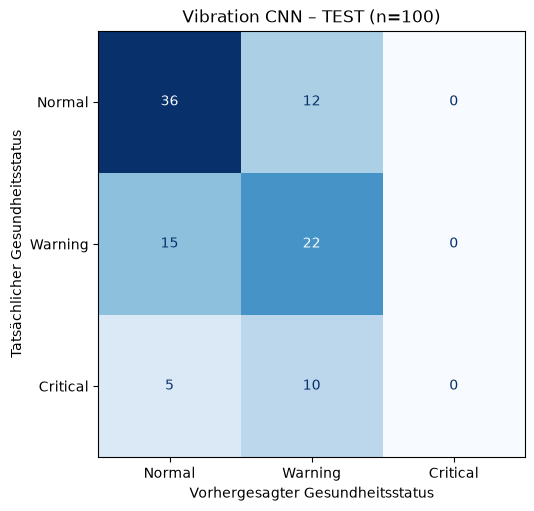

{'accuracy': 0.58, 'correct': 58, 'test': 100, 'seed': 42, 'epochs': 30, 'batch_size': 16, 'parameters': 3843, 'torch': '2.9.1+cpu', 'cpu_threads': 1, 'raw_sha256': '3f7a7e52bd2b0efd0f3af43b07efa2c05620589a09d67d82519598f6f99d6d03'}


In [4]:
torch.manual_seed(SEED)
ts_loader=DataLoader(TensorDataset(ts_train_tensor,y_train_tensor),batch_size=16,shuffle=True)
model_ts=train_model(TimeSeriesCNN(),ts_loader,epochs=30)
ts_test_probs=predict_proba(model_ts,ts_test_tensor)
ts_pred=ts_test_probs.argmax(axis=1)
cm=confusion_matrix(y_test,ts_pred,labels=[0,1,2])
fig,ax=plt.subplots(figsize=(6,5),layout="constrained")
ConfusionMatrixDisplay.from_predictions(y_test,ts_pred,labels=[0,1,2],display_labels=NAMES,ax=ax,cmap="Blues",colorbar=False)
ax.set(title="Vibration CNN – TEST (n=100)",xlabel="Vorhergesagter Gesundheitsstatus",ylabel="Tatsächlicher Gesundheitsstatus")
fig.savefig(output/"02_confusion_matrix.png",dpi=150,bbox_inches="tight")
plt.show()
predictions=pd.DataFrame({"Index_0basiert":prepared["test_indices"],"Ist":y_test,"Vorhersage":ts_pred,**{f"p_{name}":ts_test_probs[:,i] for i,name in enumerate(NAMES)}})
predictions.to_csv(output/"predictions.csv",index=False)
pd.DataFrame(cm,index=NAMES,columns=NAMES).to_csv(output/"confusion_matrix.csv")
summary={"accuracy":float(accuracy_score(y_test,ts_pred)),"correct":int((ts_pred==y_test).sum()),"test":len(y_test),"seed":SEED,"epochs":30,"batch_size":16,"parameters":sum(p.numel() for p in model_ts.parameters()),"torch":torch.__version__,"cpu_threads":torch.get_num_threads(),"raw_sha256":RAW_SHA256}
(output/"summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
print(summary)


### Was lässt sich aus Vibration lernen?
Die verborgenen Levels werden erst zur Diagnose mit den Ergebnissen verglichen. Laut Definition hängt Gesundheit von beiden Modalitäten ab: Bei Vibrationslevel 0/1 kann die thermische Stufe zu Normal, Warning oder Critical führen. Bei Vibrationslevel 2 ergeben thermische Stufen 0/1/2 Warning/Critical/Critical. Aus Vibration allein ist diese thermische Information nicht eindeutig verfügbar. Eine Critical-Vorhersage wäre deshalb nicht grundsätzlich unmöglich, aber keine sichere Diagnose nur aus diesem Signal.

In [5]:
def levels_vs_status(level: np.ndarray,pred: np.ndarray,level_name: str)->pd.DataFrame:
    """Official diagnostic helper; uses TEST truth, never training inputs."""
    return pd.concat([pd.crosstab(level,y_test,colnames=["status"]),pd.crosstab(level,pred,colnames=["status"])],axis=1,keys=["true health status","predicted health status"]).rename_axis(level_name)
vibration_comparison=levels_vs_status(levels_test[:,1],ts_pred,"vibration level")
display(vibration_comparison)
vibration_comparison.to_csv(output/"vibration_levels_vs_status.csv")
print("Vorhersagehäufigkeiten:",dict(zip(NAMES,np.bincount(ts_pred,minlength=3).tolist())))
split=pd.DataFrame({"Index_0basiert":np.r_[prepared["train_indices"],prepared["test_indices"]],"Split":["TRAIN"]*400+["TEST"]*100})
split.to_csv(output/"split.csv",index=False)


true health status        predicted health status    
status                           0   1  2                       0   1
vibration level                                                      
0                               33  12  5                      50   0
1                               15  12  2                       6  23
2                                0  13  8                       0  21

Vorhersagehäufigkeiten: {'Normal': 56, 'Warning': 44, 'Critical': 0}


### Interpretation und Grenzen
Das CNN klassifiziert **58/100 TEST-Beobachtungen korrekt (Accuracy 0,58)**. Normal wird bei 36/48, Warning bei 22/37 erkannt. Alle 15 Critical-Fälle werden übersehen: fünf als Normal, zehn als Warning. Das Modell sagt insgesamt 56-mal Normal und 44-mal Warning voraus, niemals Critical.

Die Kreuztabelle zeigt: Vibrationslevel 0 wird immer als Normal eingestuft (50 Fälle), Level 2 immer als Warning (21 Fälle); bei Level 1 entstehen sechs Normal- und 23 Warning-Vorhersagen. Das passt zu einem überwiegend nach Vibrationsniveau trennenden Modell, ist aber kein Beweis für eine vollständig gelernte Level-Erkennung. Die wahren Klassen bleiben innerhalb jedes Levels gemischt. Bei Level 2 stehen beispielsweise 13 Warning- acht Critical-Fällen gegenüber. Dass hier keine Critical-Vorhersage entsteht, ist angesichts fehlender thermischer Information und seltener Critical-Fälle plausibel; es ist weder zwingend für jedes CNN noch für Sicherheitsüberwachung ausreichend. Gesundheitsunterschiede durch thermische Zustände bleiben mit diesem Input nicht eindeutig zugänglich. Die kleine synthetische Stichprobe und ein einziger fester Split erlauben keine allgemeine Aussage über reale Maschinen. Keine externe Validierung, keine Optimierung nach TEST-Ergebnissen und kein Nachweis über Overfitting ohne gesonderte Validierungsdaten. Numerische Wiederholbarkeit gilt für die dokumentierte CPU-Umgebung, nicht automatisch bitweise für andere Plattformen.

KI-Unterstützung: Codex las die Vorgaben, ergänzte das CNN und die Auswertung und führte technische Prüfungen aus. Studentischer Human Review steht aus. **AWAITING HUMAN REVIEW.**